# 02 — Data and point-in-time checks / 資料與時點正確性檢查

**EN** How the dataset is rebuilt, what it covers, and live point-in-time tests on the real data (prefix stability, universe recomputed by hand, a feature recomputed from the raw CSV, no holdout price in open labels).

*Needs `data/` and `artifacts/` from the shared Drive folder (see README).*

**中文** 資料如何重建、涵蓋範圍，並直接在真實資料上執行時點正確性測試（前綴穩定性、手算股票池、從原始 CSV 重算特徵、開放標籤不含 holdout 價格）。

*需要先從 README 的 Drive 連結下載 `data/` 與 `artifacts/`。*

In [1]:
# Locate the repository root and load the library (works from the root or notebooks/)
# 找到 repo 根目錄並載入函式庫（從根目錄或 notebooks/ 執行皆可）
import os, sys, json, subprocess
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "setup.yaml").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)


def show(fig, width=820):
    """Show a committed figure / 顯示已產出的圖"""
    display(Image(filename=str(ROOT / "reports" / "figures" / fig), width=width))


def sh(cmd):
    """Run a repository command from the root and print its output / 在根目錄執行指令並印出結果"""
    r = subprocess.run(cmd, shell=True, cwd=ROOT, capture_output=True, text=True, encoding="utf-8")
    print(r.stdout[-4000:], r.stderr[-2000:])
    return r.returncode

## Rebuild
**EN** From the root: `python scripts/download_funding_settlements.py --end 2026-10-25`, then `python scripts/build_dataset.py` and `python scripts/data_quality_report.py`. The manifest records the SHA-256 of every input.

## 重建
**中文** 在根目錄依序執行上面三個指令。manifest 記錄每個輸入檔的 SHA-256，可檢查資料是否一致。

In [2]:
# Input hashes of the processed snapshot / 處理後快照的輸入檔雜湊
man = json.loads(Path("data/processed/manifest.json").read_text())
print("snapshot end / 快照截止:", yaml.safe_load(open("setup.yaml", encoding="utf-8"))["data"]["snapshot_end_exclusive"])
pd.DataFrame(man["inputs"]).T[["sha256"]].assign(sha256=lambda d: d["sha256"].str[:16])

snapshot end / 快照截止: 2026-10-25


,sha256
daily_bars,aaf1e39326093168
funding_settlements,fdc3c5f461467de8
metrics,a17d6820d7eef77c


min       1.000
mean     85.088
max     100.000
dtype: float64
contracts ever seen / 曾出現的合約數: 670


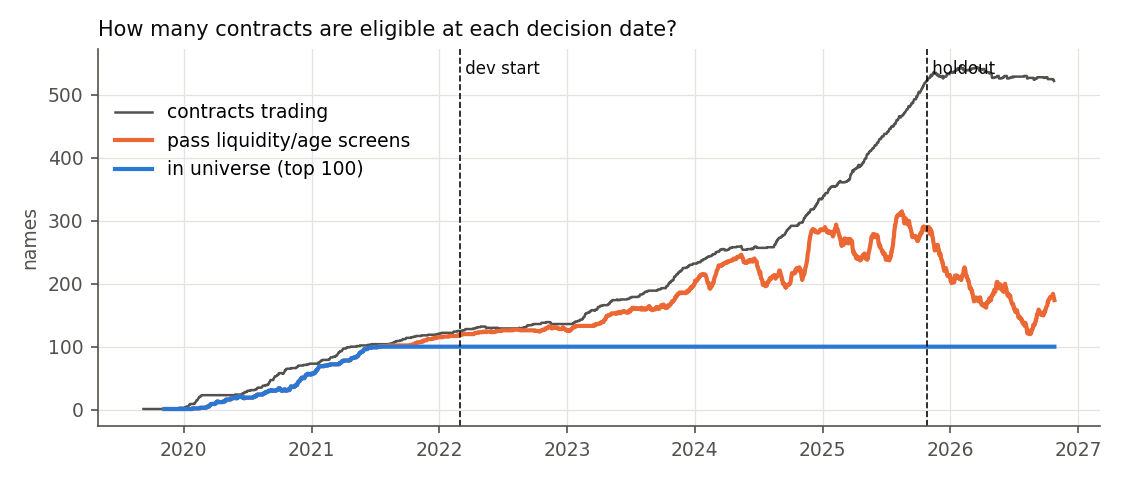

In [3]:
# Universe coverage over time: eligible contracts per decision date / 每個決策日的合格合約數
uni = pd.read_parquet("data/processed/universe.parquet", columns=["date", "symbol", "in_universe", "exclusion"])
cov = uni[uni["in_universe"]].groupby("date").size()
print(cov.describe()[["min", "mean", "max"]])
print("contracts ever seen / 曾出現的合約數:", uni["symbol"].nunique())
show("coverage.png")

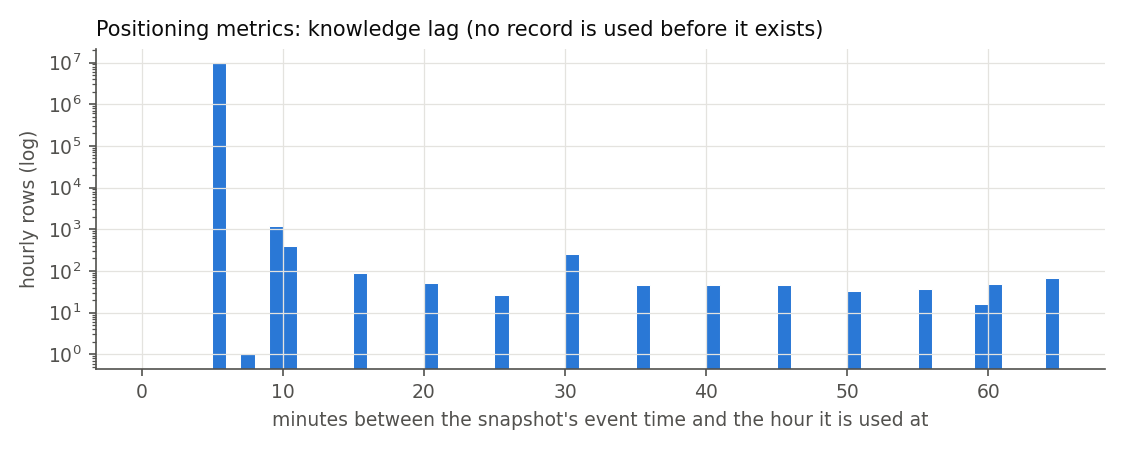

In [4]:
# Knowledge lag of non-price data (zero-lag rows would be a red flag) / 非價格資料的可得延遲
show("knowledge_lag.png")

## Live point-in-time tests
**EN** These run on the real processed data, not on fixtures.

## 即時時點測試
**中文** 直接跑在真實處理後資料上，不是假資料。

In [5]:
# Point-in-time tests on the real data / 真實資料上的時點正確性測試
sh("python -m pytest -q --color=no tests/test_pit_real.py tests/test_sealing.py tests/test_holdout_guard.py")

..............                                                           [100%]
14 passed in 34.31s
 


0

In [6]:
# Full data-quality report / 完整資料品質報告
display(Markdown(Path("reports/data_quality.md").read_text(encoding="utf-8")[:6000]))

# Data quality report

Generated by `scripts/data_quality_report.py` from the dataset built at
`2026-10-26T15:48:53+00:00` (git `e5c741a`, setup `v1`,
snapshot end `2026-10-25` exclusive). Rebuild with
`python scripts/build_dataset.py`. Inputs and their SHA-256 are in `data/processed/manifest.json`.

## 1. Sources and timestamp semantics

| Dataset | Source | Event time | Knowable at |
|---|---|---|---|
| Daily bars | Binance `/fapi/v1/klines` 1d | `date` = UTC 00:00 open | close at `date + 1 day` |
| Funding settlements | Binance `/fapi/v1/fundingRate` (downloaded 2026-10-26T15:48:17+00:00) | `fundingTime` | `fundingTime + 1 min` |
| Positioning metrics | data.binance.vision `um/daily/metrics`, 5-min snapshots, resampled hourly | snapshot `create_time` | `create_time + 5 min` (verified against the live API, see `data/DATA_QUALITY.md` §5) |

- **Session**: crypto trades 24/7. Every calendar day is a trading day and all buffers count calendar days. The decision clock is 00:00 UTC.
- **Storage**: Parquet files in `data/processed/` (`universe`, `settlements`, `features`, `labels`), regenerated end to end by `scripts/build_dataset.py`.
- **Synthetic data**: none.

## 2. Daily bars

| check | value |
|---|---|
| rows | 635604 |
| symbols | 670 |
| first_date | 2019-09-08 |
| last_date | 2026-10-24 |
| duplicate_keys | 0 |
| nan_values | 0 |
| invalid_bars_zero_volume_or_price | 54247 |
| ohlc_nonpositive | 0 |
| ohlc_high_below_open_close | 0 |
| ohlc_low_above_open_close | 0 |
| ohlc_high_below_low | 0 |
| missing_days_inside_contract_life | 0 |
| abs_daily_return_gt_50pct | 946 |

- **Invalid bars**: zero-volume bars are listed but not trading, either before listing or after delisting. They are kept and flagged, are never forward-filled, and never count as a fill or as a return.
- **Extreme returns**: the 946 daily moves above 50% are kept. The redenomination screen in section 3 found no unit change among them, so they are treated as real price moves.

## 3. Corporate-action check (crypto analogue)

Perpetuals have no splits or dividends. The two analogues are exchange redenominations
and contract multipliers.

**Redenomination screen**: a close/previous-close ratio within 2% of a power of ten.
A redenomination would gap at the open; a genuine crash opens near the previous close.

| date | symbol | prev_close | open | close | close_over_prev | open_over_prev | verdict |
|---|---|---|---|---|---|---|---|
| 2026-03-03 00:00:00 | POWERUSDT | 1.82383 | 1.82324 | 0.18213 | 0.0999 | 0.9997 | genuine move (no gap at open) |
| 2026-04-24 00:00:00 | TRADOORUSDT | 8.334 | 8.337 | 0.856 | 0.1027 | 1.0004 | genuine move (no gap at open) |

**Multiplier contracts** (prices quoted per 1000 or more units; returns are unaffected,
price levels are not comparable across names): 14 contracts, for example
1000000BOBUSDT, 1000000MOGUSDT, 1000BONKUSDT, 1000CATUSDT, 1000CHEEMSUSDT, 1000FLOKIUSDT. No feature uses a price level.

## 4. Funding settlements

| check | value |
|---|---|
| rows | 2687127 |
| symbols | 670 |
| old_contract_rows_dropped | 26312 |
| duplicate_settlements | 0 |
| nan_rates | 0 |
| abs_rate_gt_1pct | 2754 |
| max_abs_rate | 0.04 |
| timestamp_jitter_ms_max | 47.0 |
| intervals_over_8h | 0 |

- **Settlement interval** (hours between consecutive settlements, current contracts only):

| hours | count |
|---|---|
| 1.0 | 80040 |
| 2.0 | 3434 |
| 3.0 | 49 |
| 4.0 | 1609724 |
| 5.0 | 1 |
| 6.0 | 4 |
| 8.0 | 966893 |

- **Reconciliation** with the legacy daily sums in `data/UNIVERSE/funding_daily.csv`:

| check | value |
|---|---|
| overlapping_symbol_days | 601928 |
| match_within_1e-9 | 1.0 |
| max_abs_diff | 9.999054535747565e-17 |
| days_only_in_settlements | 91 |

- **Old-contract rows**: settlements dated before a relisted ticker's first price bar belong to the previous contract and are dropped. Example tickers: BNTUSDT, OGUSDT, RIFUSDT.
- **Contracts with no settlement data**: 0 in total; 0 of them ever in the universe (none). Their rows have no `fund_7d`, so they leave the modeling sample.

## 5. Positioning metrics

| check | value |
|---|---|
| rows | 10590144 |
| symbols | 650 |
| first_ts | 2020-09-01 00:00:00 |
| last_ts | 2026-10-24 23:00:00 |
| duplicate_keys | 0 |
| snapshot_lag_minutes_p50_p99_max | [0.0, 0.0, 60.0] |
| knowledge_lag_note | ts = snapshot create_time + 5 min; snap_lag is extra staleness |

Missing share by column (all hourly rows):

| column | nan_share |
|---|---|
| oi | 0.0954 |
| top_pos_lsr | 0.19 |
| global_acct_lsr | 0.1012 |
| taker_lsvr_1h | 0.1324 |
| snap_lag_min | 0.0954 |

**Known gaps** (dev-period quarters where a feature is missing for more than 20% of
in-universe rows; the archive files exist but these columns are empty):

| feature | quarters_over_20pct_missing | worst_share |
|---|---|---|
| lsr_div | 2022Q1, 2022Q2, 2022Q3, 2022Q4 | 0.999 |
| lsr_div_chg_7d | 2022Q1, 2022Q2, 2022Q3, 2022Q4 | 1.0 |
| tplsr_z_30d | 2022Q1, 2022Q2, 2022Q3, 2022Q4 | 1.0 |
| taker_24h | 2022Q1, 2022Q2 | 0.999 |
| taker_7d | 2022Q1, 2022Q2 | 1.0 |

These features follow `features.missing_policy` in `setup.yaml`: neutral rank plus a
missing flag, never a time-series fill.

![knowledge lag](figures/knowledge_lag.png)

## 6. Universe and survivorship

- **Rule**: top 100 by mean quote volume over days d-30..d-1. Screens: median ≥ $5,000,000, listed ≥ 60 days, traded on d-1. Excluded symbols: USDCUSDT, PAXGUSDT, XAUTUSDT, DEFIUSDT, BTCDOMUSDT.
- **Names per decision date from dev start**: min 100, median 100, max 100.

| check | value |
|---|---|
| decision_dates | 2545 |
| names_ever_in_universe | 547 |
| leavers_count | 11 |
| leavers_by_year | {2020: 1, 2022: 3, 2024: 6, 2026: 1} |
| exclusion_counts | {'in_universe': 216549, 'illiquid': 160414, 'outside_top_n': 159347, 'too_young': 39172, 'excluded_symbol': 5875} |

- **Leavers** (contracts that were in the universe and stopped trading before the snapshot end): AKROUSDT, ANCUSDT, BTSUSDT, COCOSUSDT, FOOTBALLUSDT, HNTUS